# Sesión 05 - IA en Python con cuaderno de Jupyer en Colaboratory

Instrucciones:

1. Para ejecutar una celda hay que utilizar ctrl+shift, lo cual generará el resultado del código más una nueva celda de programación.

2. Previamente a la ejecución del cuaderno, hay que verificar que tenemos conectadi la distribución de Python. Normalmente se aloja en la parte superior derecha de la interfaz de Google Colaboratory.

In [1]:
# Instalar paquetes necesarios

%pip install -U google groq openai ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 14.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 23.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 33.5 MB/s  0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninstalled widgetsnbextension-3.6.10
  Attempting uninstall: openai
    Found existing installation: openai 2.54.0
    Uninstalling openai-2.54.0:
      Successfully uninstalled openai-2.54.0
  Attempting uninstall: ipywidgets
    Found existing installation: ipywidgets 7.7.1
    Uninstalling ipywidgets-7.7.1:
      Successfully uninstalled ipywidgets-7.7.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [groq]


In [2]:
# Importaciones comunes

import os
from getpass import getpass
import ipywidgets as widgets
from IPython.display import display, clear_output

In [3]:
# Elegir proveedor y preparar la clave

proveedor = "groq"

variables_api = {
    "gemini": "GEMINI_API_KEY",
    "groq":"GROQ_API_KEY",
    "openrouter": "OPENROUTER_API_KEY"
}

if proveedor not in variables_api:
  raise ValueError("Elige gemini, groq u openrouter.")

clave_api = os.environ.get(variables_api[proveedor], "").strip()
if not clave_api:
  clave_api = getpass(f"Clave de provedor {proveedor}: ").strip()
if not clave_api:
  raise ValueError("La clave no puede estar vacía.")

print("Proveedor seleccionado:", proveedor)

Clave de provedor groq: ··········
Proveedor seleccionado: groq


In [4]:
# Creación de la conexión

if proveedor == "gemini":
  from google import genai
  from google.genai import types
  cliente = genai.Client(
      api_key = clave_api,
      http_options={"timeout": 120000}
  )

elif proveedor == "groq":
    from groq import Groq
    cliente = Groq(api_key = clave_api, timeout = 120.0, max_retries=0)

else:
  from openai import OpenAI
  cliente = OpenAI(
      api_key = clave_api,
      base_url = "https://openrouter.ai/api/v1",
      timeout = 120.0,
      max_retries=0
  )

# La clave (api) sigue en la memoria interna del cliente, pero vamos a quitar esa copia
del clave_api
print("Cliente creado. El siguiente paso es consultar el catálogo")

Cliente creado. El siguiente paso es consultar el catálogo


In [5]:
# Consultar modelos disponibles

if proveedor == "gemini":
  catalogo = list(cliente.models.list())
  modelos = sorted(
      m.name.removeprefix("models/")
      for m in catalogo
      if "generateContent" in (m.supported_actions or [])
  )

else:
  catalogo = cliente.models.list()
  modelos = sorted(m.id for m in catalogo.data)

print("Modelos encontrados: ", len(modelos))
for nombre in modelos:
  print(nombre)

Modelos encontrados:  11
allam-2-7b
canopylabs/orpheus-arabic-saudi
canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-22m
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-120b
openai/gpt-oss-20b
openai/gpt-oss-safeguard-20b
qwen/qwen3.8-27b
whisper-large-v3
whisper-large-v3-turbo


In [6]:
# Elegir modelo y abrir una conversación

modelo = input("ID del modelo de texto/chat: ").strip()
if not modelo:
  raise ValueError("Debes indicar un modelo.")

sistema = (
    "Eres un tutor experto en Python y análisis de datos. Responde en español, "
    "paso a paso, con código separado en celdas para Jupyter. Explica supuestos "
    "e interpretación de las salidas. No inventes datos, resultados ni ejecuciones."
)

historial = [{"role": "system", "content": sistema}]

if proveedor == "gemini":
  chat = cliente.chats.create(
      model = modelo,
      config = types.GenerateContentConfig(system_instruction = sistema),
  )
print("Conversación preparada con:", proveedor, "/", modelo)

ID del modelo de texto/chat: openai/gpt-oss-120b
Conversación preparada con: groq / openai/gpt-oss-120b


In [7]:
# Primera consulta: Sin definir funciones

prompt = "Explica qué es un DataFrame de pandas y muestra un ejemplo con tres filas."

if proveedor == "gemini":
  respuesta = chat.send_message(prompt)
  texto = respuesta.text
else:
  mensajes = historial + [{"role": "user", "content":prompt}]
  respuesta = cliente.chat.completions.create(
      model = modelo,
      messages = mensajes
  )
  texto = respuesta.choices[0].message.content

if not texto or not texto.strip():
  raise ValueError("No se recibió texto. Revisa el modelo o el motivo de bloqueo")

if proveedor != "gemini":
  historial.extend([
      {"role": "user", "content": prompt},
      {"role": "assistant", "content":texto}
  ])

print(texto)

## ¿Qué es un **DataFrame** de **pandas**?

Un **DataFrame** es la estructura de datos tabular fundamental de la librería **pandas**.  
Podemos pensar en él como una hoja de cálculo o una tabla SQL con las siguientes características:

| Característica | Descripción |
|----------------|-------------|
| **Filas**      | Cada fila representa una observación o registro. |
| **Columnas**   | Cada columna tiene un nombre y contiene datos de un mismo tipo (numérico, texto, fechas, etc.). |
| **Índice**     | pandas asigna un índice (por defecto 0, 1, 2, …) que permite acceder rápidamente a filas específicas. |
| **Operaciones vectorizadas** | Las operaciones se aplican a columnas completas sin necesidad de bucles explícitos, lo que hace el código más rápido y legible. |
| **Manejo de datos faltantes** | pandas incluye herramientas para detectar, eliminar o imputar valores `NaN`. |
| **Integración**| Se combina fácilmente con otras librerías de ciencia de datos (NumPy, Matplotlib, scikit‑learn

## ¿Qué es un **DataFrame** de **pandas**?

Un **DataFrame** es la estructura de datos tabular fundamental de la librería **pandas**.  
Podemos pensar en él como una hoja de cálculo o una tabla SQL con las siguientes características:

| Característica | Descripción |
|----------------|-------------|
| **Filas**      | Cada fila representa una observación o registro. |
| **Columnas**   | Cada columna tiene un nombre y contiene datos de un mismo tipo (numérico, texto, fechas, etc.). |
| **Índice**     | pandas asigna un índice (por defecto 0, 1, 2, …) que permite acceder rápidamente a filas específicas. |
| **Operaciones vectorizadas** | Las operaciones se aplican a columnas completas sin necesidad de bucles explícitos, lo que hace el código más rápido y legible. |
| **Manejo de datos faltantes** | pandas incluye herramientas para detectar, eliminar o imputar valores `NaN`. |
| **Integración**| Se combina fácilmente con otras librerías de ciencia de datos (NumPy, Matplotlib, scikit‑learn, etc.). |

En resumen, un DataFrame es una **estructura de datos bidimensional** (filas × columnas) que permite **manipular, limpiar y analizar** datos de forma eficiente en Python.

---

## Ejemplo práctico: crear un DataFrame con tres filas

A continuación, mostraremos paso a paso cómo crear un DataFrame sencillo que contiene información de tres personas: su nombre, edad y ciudad de residencia.

### 1️⃣ Importar la librería `pandas`

```python
import pandas as pd
```

### 2️⃣ Definir los datos

Podemos definir los datos como una lista de diccionarios (cada diccionario corresponde a una fila) o como un diccionario de listas (cada lista corresponde a una columna).  
Usaremos la primera opción porque es muy legible cuando el número de filas es pequeño.

```python
# Cada diccionario representa una fila
datos = [
    {"nombre": "Ana",   "edad": 28, "ciudad": "Madrid"},
    {"nombre": "Luis",  "edad": 34, "ciudad": "Barcelona"},
    {"nombre": "Marta", "edad": 22, "ciudad": "Valencia"}
]
```

### 3️⃣ Crear el DataFrame

```python
df = pd.DataFrame(datos)
```

### 4️⃣ Visualizar el DataFrame

```python
df
```

#### Interpretación de la salida esperada

Al ejecutar la celda anterior en un cuaderno Jupyter, el kernel mostrará algo parecido a:

```
  nombre  edad     ciudad
0    Ana    28      Madrid
1   Luis    34   Barcelona
2  Marta    22    Valencia
```

- **Índice** (`0`, `1`, `2`): Identificador implícito que pandas asigna a cada fila.
- **Columnas** (`nombre`, `edad`, `ciudad`): Cada una tiene su propio tipo de dato (texto para `nombre` y `ciudad`, entero para `edad`).
- **Filas**: Cada registro contiene la información de una persona.

---

## Paso extra: acceder a los datos

Una vez creado el DataFrame, podemos **consultar** o **manipular** su contenido sin escribir bucles explícitos.

```python
# 1. Seleccionar la columna 'edad' (devuelve una Serie de pandas)
edades = df["edad"]
edades
```

```
0    28
1    34
2    22
Name: edad, dtype: int64
```

```python
# 2. Filtrar personas mayores de 25 años
mayores_25 = df[df["edad"] > 25]
mayores_25
```

```
  nombre  edad     ciudad
0    Ana    28      Madrid
1   Luis    34   Barcelona
```

```python
# 3. Añadir una nueva columna calculada: año de nacimiento (suponiendo el año actual 2026)
df["año_nacimiento"] = 2026 - df["edad"]
df
```

```
  nombre  edad     ciudad  año_nacimiento
0    Ana    28      Madrid            1998
1   Luis    34   Barcelona            1992
2  Marta    22    Valencia            2004
```

---

## Resumen

- Un **DataFrame** es una tabla de datos con filas y columnas, muy útil para análisis de datos en Python.
- Se crea a partir de estructuras nativas de Python (listas, diccionarios, arrays de NumPy, etc.).
- Pandas facilita la **visualización**, **selección**, **filtrado** y **transformación** de los datos mediante una sintaxis clara y operaciones vectorizadas.

Con estos conceptos y el ejemplo presentado, ya puedes comenzar a trabajar con DataFrames en tus propios proyectos de análisis de datos. ¡A practicar! 🚀

In [8]:
from google.colab import output

output.enable_custom_widget_manager()

In [9]:
# Crear el cuadro de texto

if "panel_ia" in globals():
    panel_ia.close()

entrada = widgets.Textarea(
    value="",
    placeholder="Escribe una pregunta o pega código y explica qué necesitas…",
    description="Prompt:",
    layout=widgets.Layout(width="100%", height="180px"),
)
boton = widgets.Button(
    description="Consultar IA",
    icon="paper-plane",
    button_style="warning",
    tooltip="Enviar el prompt al proveedor seleccionado",
)
salida = widgets.Output()

print("Controles preparados. Ejecuta la siguiente celda para activar el botón.")



Controles preparados. Ejecuta la siguiente celda para activar el botón.


In [10]:
# Activar el botón: la única función

def al_consultar(b):
    pregunta = entrada.value.strip()
    with salida:
        clear_output(wait=True)
        if not pregunta:
            print("Primero escribe una pregunta.")
            return

        b.disabled = True
        b.description = "Consultando…"
        try:
            if proveedor == "gemini":
                resultado = chat.send_message(pregunta)
                texto_respuesta = resultado.text
            else:
                mensajes = historial + [{"role": "user", "content": pregunta}]
                resultado = cliente.chat.completions.create(
                    model=modelo,
                    messages=mensajes,
                )
                texto_respuesta = resultado.choices[0].message.content

            if not texto_respuesta or not texto_respuesta.strip():
                raise ValueError("Respuesta sin texto.")

            if proveedor != "gemini":
                historial.extend([
                    {"role": "user", "content": pregunta},
                    {"role": "assistant", "content": texto_respuesta},
                ])
            print(texto_respuesta)

        except Exception as error:
            print("No se completó la consulta:", type(error).__name__)
            print("Revisa clave, modelo, permisos, cuota y conexión.")
        finally:
            b.disabled = False
            b.description = "Consultar IA"

In [11]:
# Evita registrar el mismo evento varias veces al repetir esta celda.
if "evento_ia" in globals():
    boton.on_click(evento_ia, remove=True)
evento_ia = al_consultar
boton.on_click(evento_ia)

if "panel_ia" in globals():
    panel_ia.close()
panel_ia = widgets.VBox([entrada, boton, salida])
display(panel_ia)

## 📚 Paso a paso – Descargar datos de **AAPL**, calcular medias móviles y graficar  

A continuación tienes el código dividido en celdas listo para copiar en un cuaderno Jupyter. Cada celda incluye **comentarios** que explican qué hace y **por qué** es necesario. No se generan resultados ficticios; el código se ejecutará en tu entorno y mostrará los valores reales que descargue `yfinance`.

---

### 1️⃣  Importar librerías y configurar estilo visual

```python
# Cell 1: Importaciones y estilo de la gráfica
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Estilo "profesional" (puedes cambiarlo a tu gusto)
plt.style.use('seaborn-darkgrid')

# Opciones de pandas para una mejor visualización en notebooks
pd.set_option('display.max_columns', None)   # mostrar todas las columnas
pd.set_option('display.width', 1000)        # ancho suficiente para no cortar
```

**Explicación**  
- `pandas` para manipular los datos.  
- `yfinance` para descargar la serie histórica de precios.  
- `matplotlib.pyplot` para graficar.  
- El estilo `seaborn-darkgrid` brinda colores suaves y una cuadrícula clara, lo que hace que la figura luzca más “corporativa”.  

---

### 2️⃣  Descargar datos de Apple (AAPL) sin ajuste automático  

```python
# Cell 2: Descarga de datos
ticker = "AAPL"

# auto_adjust=False conserva los precios originales (Open, High, Low, Close, Adj Close, Volume)
df_raw = yf.download(tickers=ticker,
                     period="max",          # todo el histórico disponible
                     interval="1d",         # datos diarios
                     auto_adjust=False,     # NO ajustar automáticamente
                     progress=False)       # suprime la barra de progreso

# Mostrar las primeras filas para inspeccionar la tabla
df_raw.head()
```

**Qué esperar**  
- `df_raw` tiene **una sola columna (`Adj Close`)** cuando se descarga un único ticker, pero **el índice de columnas es un `MultiIndex`** si se solicitan varios tickers o varios atributos a la vez.  
- Con `auto_adjust=False` obtendrás tanto el precio **Close** como el **Adj Close**, lo que nos permitirá comparar ambos.  

---

### 3️⃣  Verificar la estructura de columnas (MultiIndex)  

```python
# Cell 3: Inspección de los nombres de columnas
print("Tipo de índice de columnas:", type(df_raw.columns))
print("\nNiveles del MultiIndex (si existe):")
if isinstance(df_raw.columns, pd.MultiIndex):
    print(df_raw.columns.names)
    display(df_raw.columns)
else:
    print("No hay MultiIndex – las columnas son de nivel único.")
```

**Interpretación**  
- Si el resultado indica que `df_raw.columns` es un `MultiIndex`, tendremos que **seleccionar** la columna `Adj Close` usando una tupla `(ticker, "Adj Close")`.  
- Si es un `Index` plano (caso típico con un solo ticker), basta con `df_raw["Adj Close"]`.  

---

### 4️⃣  Extraer la columna *Adj Close* y crear una serie con índice de fechas  

```python
# Cell 4: Obtención de la serie de precios ajustados
if isinstance(df_raw.columns, pd.MultiIndex):
    # Caso MultiIndex: usar la tupla (ticker, "Adj Close")
    adj_close = df_raw[(ticker, "Adj Close")]
else:
    # Caso simple
    adj_close = df_raw["Adj Close"]

# Renombrar la serie para mayor claridad
adj_close.name = "Adj Close"

# Visualizar las últimas 5 observaciones
adj_close.tail()
```

**Nota**  
- `adj_close` es un **`pd.Series`** con índice de tipo `DatetimeIndex`, lo que facilita el cálculo de medias móviles basadas en el número de observaciones (días).  

---

### 5️⃣  Calcular medias móviles de 50 y 200 días  

```python
# Cell 5: Cálculo de medias móviles
window_50  = adj_close.rolling(window=50).mean()
window_200 = adj_close.rolling(window=200).mean()

# Combinar todo en un DataFrame único para graficar fácilmente
df_plot = pd.concat([adj_close, window_50, window_200], axis=1)
df_plot.columns = ["Adj Close", "MA 50", "MA 200"]

# Mostrar un segmento representativo (últimos 10 días)
df_plot.tail(10)
```

**Qué hace**  
- `rolling(window=n).mean()` calcula la **media móvil simple (SMA)** de `n` observaciones consecutivas.  
- La concatenación (`pd.concat`) genera un DataFrame con tres columnas: el precio ajustado y las dos medias móviles, listo para la visualización.  

---

### 6️⃣  Graficar precio ajustado y medias móviles  

```python
# Cell 6: Visualización con matplotlib
fig, ax = plt.subplots(figsize=(14, 7))

# Plot de cada serie
ax.plot(df_plot.index, df_plot["Adj Close"], label="Precio Ajustado", color="#1f77b4", linewidth=1.5)
ax.plot(df_plot.index, df_plot["MA 50"],  label="Media Móvil 50 días", color="#ff7f0e", linewidth=1.2)
ax.plot(df_plot.index, df_plot["MA 200"], label="Media Móvil 200 días", color="#2ca02c", linewidth=1.2)

# Formato de la gráfica
ax.set_title("Apple (AAPL) – Precio Ajustado y Medias Móviles", fontsize=16, pad=15)
ax.set_xlabel("Fecha", fontsize=12)
ax.set_ylabel("Precio (USD)", fontsize=12)

# Mejorar legibilidad de fechas en el eje X
fig.autofmt_xdate()  # rota automáticamente las etiquetas de fecha

# Leyenda con fondo semi‑transparente
ax.legend(frameon=True, loc="upper left", fontsize=11, facecolor="white", edgecolor="gray", alpha=0.9)

# Añadir anotaciones opcionales (ejemplo: destacar último valor)
last_date = df_plot.index[-1]
last_price = df_plot["Adj Close"][-1]
ax.annotate(f"{last_price:,.2f} USD",
            xy=(last_date, last_price),
            xytext=(last_date, last_price*1.05),
            arrowprops=dict(facecolor='black', arrowstyle='->'),
            fontsize=10,
            ha='right')

# Mostrar la cuadrícula (ya activada por el estilo, pero reforzamos)
ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.show()
```

**Elementos de diseño profesional**  
- **Tamaño** (`figsize`) amplio para presentaciones.  
- **Colores** consistentes (paleta de Matplotlib por defecto, pero puedes personalizar).  
- **Líneas** con grosor diferenciado para que la serie principal destaque.  
- **Título y etiquetas** con tipografía clara y espaciado (`pad`).  
- **Leyenda** con fondo blanco y borde gris para que no tape la gráfica.  
- **Anotación** del último valor de precio, útil en reportes.  
- **Rotación automática** de fechas para evitar solapamientos.  

---

## 📌 Resumen de los pasos realizados

| Paso | Acción | Resultado esperado |
|------|--------|--------------------|
| 1️⃣ | Importar librerías y establecer estilo | Entorno listo para trabajar |
| 2️⃣ | Descargar datos de AAPL sin ajuste automático | `DataFrame` con precios originales |
| 3️⃣ | Verificar si las columnas son `MultiIndex` | Saber cómo acceder a `Adj Close` |
| 4️⃣ | Extraer la serie `Adj Close` | `Series` de precios ajustados |
| 5️⃣ | Calcular medias móviles de 50 y 200 días | DataFrame con 3 columnas (precio + 2 SMA) |
| 6️⃣ | Graficar todo con `matplotlib` | Gráfica clara y profesional del precio y sus medias móviles |

Ejecuta cada celda en orden y obtendrás la visualización real de los precios de Apple, sus medias móviles y un análisis listo para presentar. ¡Éxitos!

Tipo de índice de columnas: <class 'pandas.core.indexes.base.Index'>

Niveles del MultiIndex (si existe):
No hay MultiIndex – las columnas son de nivel único.


/tmp/ipykernel_4778/4186369079.py:81: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  last_price = df_plot["Adj Close"][-1]


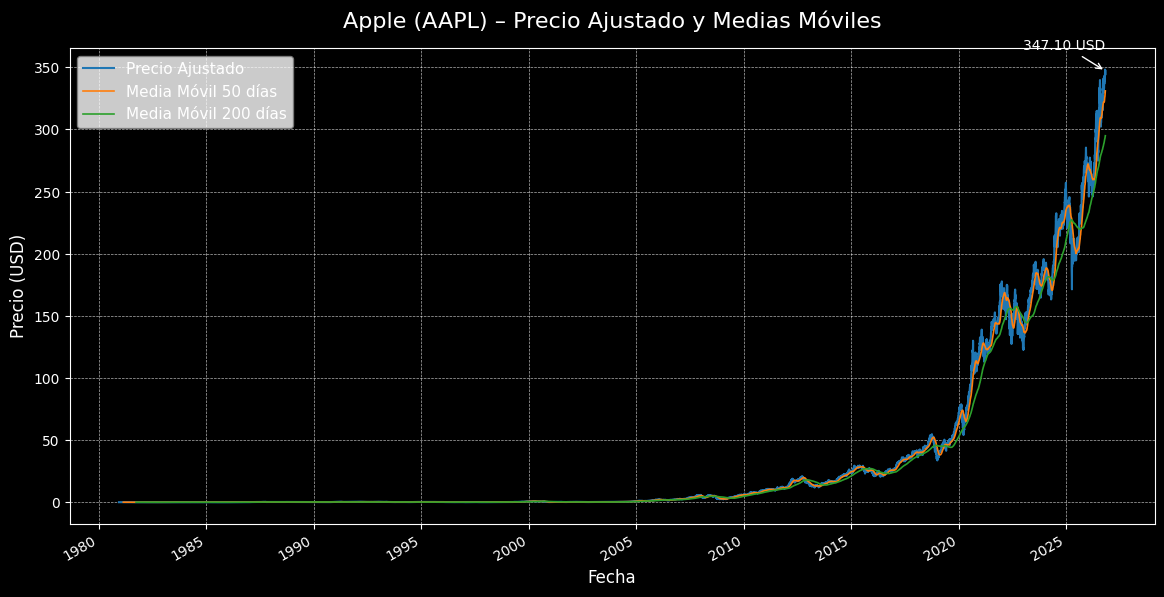

In [15]:
# Cell 1: Importaciones y estilo de la gráfica
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Estilo "profesional" (puedes cambiarlo a tu gusto)
plt.style.use('dark_background')

# Opciones de pandas para una mejor visualización en notebooks
pd.set_option('display.max_columns', None)   # mostrar todas las columnas
pd.set_option('display.width', 1000)        # ancho suficiente para no cortar

# Cell 2: Descarga de datos
ticker = "AAPL"

# auto_adjust=False conserva los precios originales (Open, High, Low, Close, Adj Close, Volume)
df_raw = yf.download(tickers=ticker,
                     period="max",          # todo el histórico disponible
                     interval="1d",         # datos diarios
                     auto_adjust=False,     # NO ajustar automáticamente
                     progress=False,
                     multi_level_index=False)       # suprime la barra de progreso

# Mostrar las primeras filas para inspeccionar la tabla
df_raw.head()

# Cell 3: Inspección de los nombres de columnas
print("Tipo de índice de columnas:", type(df_raw.columns))
print("\nNiveles del MultiIndex (si existe):")
if isinstance(df_raw.columns, pd.MultiIndex):
    print(df_raw.columns.names)
    display(df_raw.columns)
else:
    print("No hay MultiIndex – las columnas son de nivel único.")
# Cell 4: Obtención de la serie de precios ajustados
if isinstance(df_raw.columns, pd.MultiIndex):
    # Caso MultiIndex: usar la tupla (ticker, "Adj Close")
    adj_close = df_raw[(ticker, "Adj Close")]
else:
    # Caso simple
    adj_close = df_raw["Adj Close"]

# Renombrar la serie para mayor claridad
adj_close.name = "Adj Close"

# Visualizar las últimas 5 observaciones
adj_close.tail()

# Cell 5: Cálculo de medias móviles
window_50  = adj_close.rolling(window=50).mean()
window_200 = adj_close.rolling(window=200).mean()

# Combinar todo en un DataFrame único para graficar fácilmente
df_plot = pd.concat([adj_close, window_50, window_200], axis=1)
df_plot.columns = ["Adj Close", "MA 50", "MA 200"]

# Mostrar un segmento representativo (últimos 10 días)
df_plot.tail(10)

# Cell 6: Visualización con matplotlib
fig, ax = plt.subplots(figsize=(14, 7))

# Plot de cada serie
ax.plot(df_plot.index, df_plot["Adj Close"], label="Precio Ajustado", color="#1f77b4", linewidth=1.5)
ax.plot(df_plot.index, df_plot["MA 50"],  label="Media Móvil 50 días", color="#ff7f0e", linewidth=1.2)
ax.plot(df_plot.index, df_plot["MA 200"], label="Media Móvil 200 días", color="#2ca02c", linewidth=1.2)

# Formato de la gráfica
ax.set_title("Apple (AAPL) – Precio Ajustado y Medias Móviles", fontsize=16, pad=15)
ax.set_xlabel("Fecha", fontsize=12)
ax.set_ylabel("Precio (USD)", fontsize=12)

# Mejorar legibilidad de fechas en el eje X
fig.autofmt_xdate()  # rota automáticamente las etiquetas de fecha

# Leyenda con fondo semi‑transparente
ax.legend(frameon=True, loc="upper left", fontsize=11, facecolor="white", edgecolor="gray")

# Añadir anotaciones opcionales (ejemplo: destacar último valor)
last_date = df_plot.index[-1]
last_price = df_plot["Adj Close"][-1]
ax.annotate(f"{last_price:,.2f} USD",
            xy=(last_date, last_price),
            xytext=(last_date, last_price*1.05),
            arrowprops=dict(facecolor='black', arrowstyle='->'),
            fontsize=10,
            ha='right')

# Mostrar la cuadrícula (ya activada por el estilo, pero reforzamos)
ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.show()